In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import iqr
from scipy.stats import sem
from scipy.stats import norm
from scipy import stats
import statistics


In [2]:
df7a_2020_Present = pd.read_csv("FOIA_7a_FY2020_Present_asof_260630(AutoRecovered).csv")
df7a_2010_2019 = pd.read_csv("FOIA_7a_FY2010_FY2019_asof_260630 (Recovered).csv")
df504 = pd.read_csv("FOIA_504_FY2010_Present_asof_260630(AutoRecovered).csv")

C:\Users\nsoha\AppData\Local\Temp\ipykernel_19868\2121639100.py:1: DtypeWarning: Columns (0: ChargeOffDate) have mixed types. Specify dtype option on import or set low_memory=False.
  df7a_2020_Present = pd.read_csv("FOIA_7a_FY2020_Present_asof_260630(AutoRecovered).csv")
C:\Users\nsoha\AppData\Local\Temp\ipykernel_19868\2121639100.py:2: DtypeWarning: Columns (0: BankZip) have mixed types. Specify dtype option on import or set low_memory=False.
  df7a_2010_2019 = pd.read_csv("FOIA_7a_FY2010_FY2019_asof_260630 (Recovered).csv")
C:\Users\nsoha\AppData\Local\Temp\ipykernel_19868\2121639100.py:3: DtypeWarning: Columns (0: PaidInFullDate, 1: ChargeOffDate) have mixed types. Specify dtype option on import or set low_memory=False.
  df504 = pd.read_csv("FOIA_504_FY2010_Present_asof_260630(AutoRecovered).csv")


In [3]:
df7a= pd.concat([df7a_2010_2019, df7a_2020_Present])

In [4]:
df7a = pd.DataFrame(df7a)
df504 = pd.DataFrame(df504)
print(df7a.shape)
print(df504.shape)

(934089, 43)
(117983, 39)


1. Industry Risk:
Which industries have the highest charge-off rates with at least 50 loans and more? 


SBA 7(A) — INDUSTRY RISK
Eligible resolved-outcome loans: 503,965
Charged-off loans: 41,043
Overall observed charge-off rate: 8.14%
Industries meeting minimum sample size (25 loans): 839

TOP INDUSTRIES BY OBSERVED CHARGE-OFF RATE
NaicsCode                                                                         NaicsDescription  Total_Loans  Charge_Offs ChargeOff_Rate
 456120.0                                        Cosmetics, Beauty Supplies, and Perfume Retailers           65           26         40.00%
 459999.0                                                        All Other Miscellaneous Retailers          104           34         32.69%
 449210.0                                                      Electronics and Appliance Retailers           50           15         30.00%
 456191.0                                                       Food (Health) Supplement Retailers           27            8         29.63%
 459420.0                                                    Gift, N

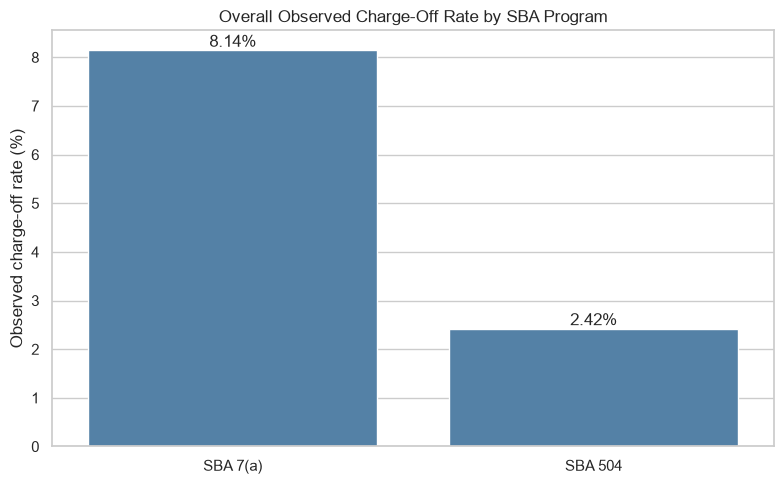

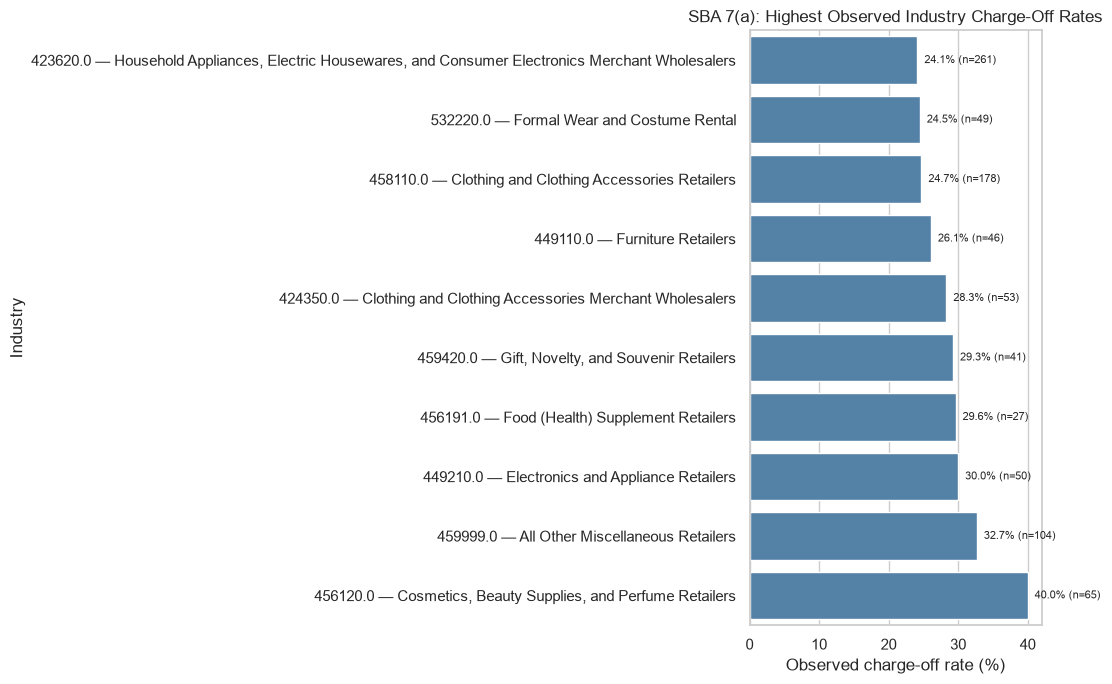

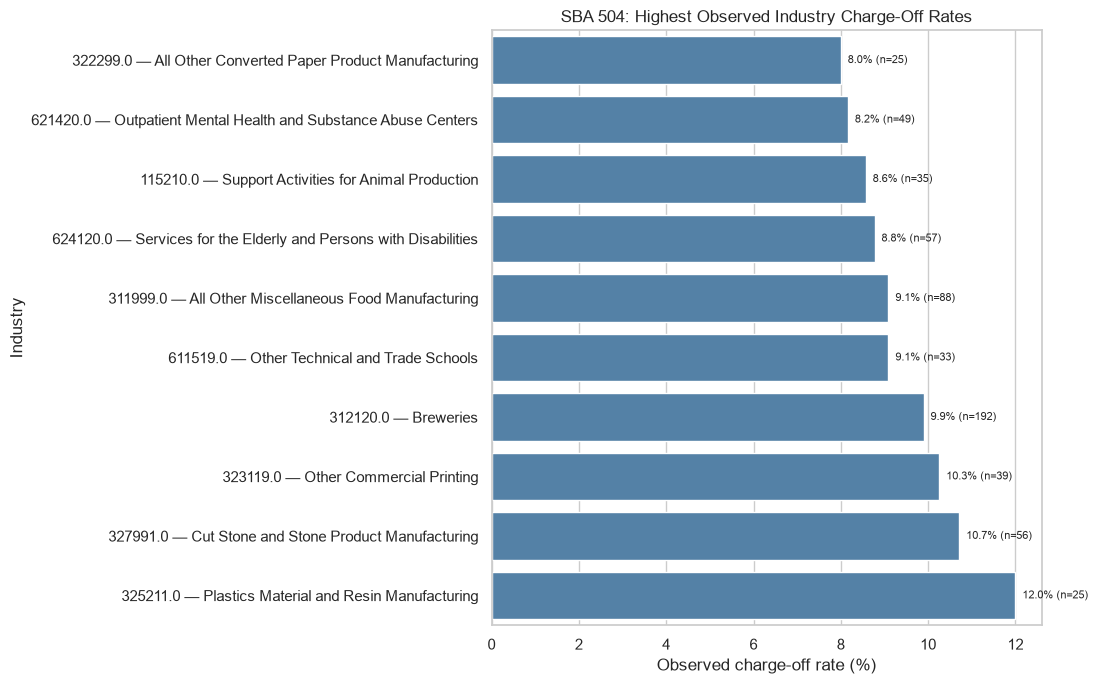


INTERPRETATION NOTES
----------------------------------------------------------------------
Rates use only records explicitly marked Paid in Full or Charged Off.
Rates describe resolved-outcome records, not all disbursed loans or lifetime default probabilities.
Industry rankings are descriptive. Small samples and differences in loan mix can affect the results.
The overall 7(a) versus 504 rate difference does not, by itself, establish that either program is inherently riskier.


In [5]:

sns.set_theme(style="whitegrid")

MIN_INDUSTRY_LOANS = 25
TOP_N = 10

def industry_risk_analysis(
    df,
    program_name,
    paid_status,
    min_loans=25,
    top_n=10
):
    """
    Calculate observed charge-off rates by industry.

    Only explicitly resolved outcomes are included:
    Paid in Full and Charged Off.
    """

    required_columns = [
        "LoanStatus",
        "NaicsDescription"
    ]

    missing_columns = [
        col for col in required_columns
        if col not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{program_name}: missing columns {missing_columns}"
        )

    # Work on a copy so the source DataFrame remains unchanged.
    data = df.copy()

    # Standardise status values.
    data["LoanStatus"] = (
        data["LoanStatus"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    # Standardise industry description.
    data["NaicsDescription"] = (
        data["NaicsDescription"]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
    )

    # Retain explicitly resolved outcomes only.
    data = data[
        data["LoanStatus"].isin([paid_status, "CHGOFF"])
    ].copy()

    # Exclude missing industry descriptions.
    data = data[
        data["NaicsDescription"].notna()
    ].copy()

    if data.empty:
        raise ValueError(
            f"{program_name}: no eligible records found. "
            "Check the status labels and industry descriptions."
        )

    # Create binary outcome.
    data["ChargeOff"] = (
        data["LoanStatus"] == "CHGOFF"
    ).astype(int)

    # Group by NAICS code AND description when the code exists.
    # Otherwise, use industry description alone.
    if "NaicsCode" in data.columns:

        data["NaicsCode"] = (
            data["NaicsCode"]
            .astype("string")
            .str.strip()
            .replace("", pd.NA)
        )

        # Preserve records without a code, but label them explicitly.
        data["NaicsCode"] = data["NaicsCode"].fillna(
            "Missing code"
        )

        group_columns = [
            "NaicsCode",
            "NaicsDescription"
        ]

    else:
        group_columns = ["NaicsDescription"]

    # Industry-level calculations.
    industry_table = data.groupby(
        group_columns,
        dropna=False
    ).agg(
        Total_Loans=("ChargeOff", "size"),
        Charge_Offs=("ChargeOff", "sum"),
        ChargeOff_Rate=("ChargeOff", "mean")
    ).reset_index()

    industry_table["ChargeOff_Rate"] *= 100

    # Apply minimum sample size.
    eligible_industries = industry_table[
        industry_table["Total_Loans"] >= min_loans
    ].copy()

    if eligible_industries.empty:
        raise ValueError(
            f"{program_name}: no industries meet the "
            f"minimum of {min_loans} eligible loans."
        )

    # Overall summary.
    total_loans = len(data)
    total_chargeoffs = int(data["ChargeOff"].sum())
    overall_rate = data["ChargeOff"].mean() * 100

    print("\n" + "=" * 70)
    print(f"{program_name.upper()} — INDUSTRY RISK")
    print("=" * 70)

    print(f"Eligible resolved-outcome loans: {total_loans:,}")
    print(f"Charged-off loans: {total_chargeoffs:,}")
    print(f"Overall observed charge-off rate: {overall_rate:.2f}%")
    print(
        f"Industries meeting minimum sample size "
        f"({min_loans} loans): {len(eligible_industries):,}"
    )

    # Highest observed rates.
    highest = eligible_industries.sort_values(
        ["ChargeOff_Rate", "Total_Loans"],
        ascending=[False, False]
    ).head(top_n)

    # Lowest observed rates.
    lowest = eligible_industries.sort_values(
        ["ChargeOff_Rate", "Total_Loans"],
        ascending=[True, False]
    ).head(top_n)

    display_columns = group_columns + [
        "Total_Loans",
        "Charge_Offs",
        "ChargeOff_Rate"
    ]

    print("\nTOP INDUSTRIES BY OBSERVED CHARGE-OFF RATE")
    print(
        highest[display_columns].to_string(
            index=False,
            formatters={
                "ChargeOff_Rate": lambda x: f"{x:.2f}%"
            }
        )
    )

    print("\nLOWEST INDUSTRIES BY OBSERVED CHARGE-OFF RATE")
    print(
        lowest[display_columns].to_string(
            index=False,
            formatters={
                "ChargeOff_Rate": lambda x: f"{x:.2f}%"
            }
        )
    )

    # Return tables for plotting and further analysis.
    return {
        "summary": {
            "Program": program_name,
            "Eligible_Loans": total_loans,
            "Charge_Offs": total_chargeoffs,
            "Overall_ChargeOff_Rate": overall_rate
        },
        "industry_table": eligible_industries,
        "highest": highest,
        "lowest": lowest,
        "group_columns": group_columns
    }

# IMPORTANT:
# 7(a) paid-in-full status is "P I F".
# 504 paid-in-full status is "PIF".

results_7a = industry_risk_analysis(
    df=df7a,
    program_name="SBA 7(a)",
    paid_status="P I F",
    min_loans=MIN_INDUSTRY_LOANS,
    top_n=TOP_N
)

results_504 = industry_risk_analysis(
    df=df504,
    program_name="SBA 504",
    paid_status="PIF",
    min_loans=MIN_INDUSTRY_LOANS,
    top_n=TOP_N
)

overall_comparison = pd.DataFrame([
    results_7a["summary"],
    results_504["summary"]
])

print("\n" + "=" * 70)
print("OVERALL PROGRAM COMPARISON")
print("=" * 70)

print(
    overall_comparison.to_string(
        index=False,
        formatters={
            "Overall_ChargeOff_Rate": lambda x: f"{x:.2f}%"
        }
    )
)

rate_difference = (
    results_7a["summary"]["Overall_ChargeOff_Rate"]
    - results_504["summary"]["Overall_ChargeOff_Rate"]
)

print(
    "\nDifference in observed rates "
    "(7(a) minus 504): "
    f"{rate_difference:.2f} percentage points"
)

plot_overall = overall_comparison.copy()

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=plot_overall,
    x="Program",
    y="Overall_ChargeOff_Rate",
    color="steelblue"
)

ax.set_title(
    "Overall Observed Charge-Off Rate by SBA Program"
)
ax.set_xlabel("")
ax.set_ylabel("Observed charge-off rate (%)")

for bar, value in zip(
    ax.patches,
    plot_overall["Overall_ChargeOff_Rate"]
):
    ax.annotate(
        f"{value:.2f}%",
        (
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

def plot_top_industries(results, program_name, top_n=10):

    table = results["highest"].copy()

    # Create readable labels, including code where available.
    if "NaicsCode" in table.columns:
        table["Industry"] = (
            table["NaicsCode"].astype(str)
            + " — "
            + table["NaicsDescription"].astype(str)
        )
    else:
        table["Industry"] = table["NaicsDescription"].astype(str)

    table = table.sort_values("ChargeOff_Rate", ascending=True)

    plt.figure(figsize=(11, 7))

    ax = sns.barplot(
        data=table,
        x="ChargeOff_Rate",
        y="Industry",
        color="steelblue"
    )

    ax.set_title(
        f"{program_name}: Highest Observed Industry Charge-Off Rates"
    )
    ax.set_xlabel("Observed charge-off rate (%)")
    ax.set_ylabel("Industry")

    for bar, (_, row) in zip(ax.patches, table.iterrows()):
        ax.annotate(
            f"{row['ChargeOff_Rate']:.1f}% (n={int(row['Total_Loans']):,})",
            (
                bar.get_width(),
                bar.get_y() + bar.get_height() / 2
            ),
            xytext=(5, 0),
            textcoords="offset points",
            va="center",
            fontsize=8
        )

    plt.tight_layout()
    plt.show()

plot_top_industries(results_7a, "SBA 7(a)", TOP_N)
plot_top_industries(results_504, "SBA 504", TOP_N)

print("\nINTERPRETATION NOTES")
print("-" * 70)
print(
    "Rates use only records explicitly marked Paid in Full "
    "or Charged Off."
)
print(
    "Rates describe resolved-outcome records, not all disbursed "
    "loans or lifetime default probabilities."
)
print(
    "Industry rankings are descriptive. Small samples and differences "
    "in loan mix can affect the results."
)
print(
    "The overall 7(a) versus 504 rate difference does not, by itself, "
    "establish that either program is inherently riskier."
)


2. Loan Characteristics = 
7(a): How do loan characteristics vary across SBA 7(a) loans, and what loan characteristics are associated with charge-off risk?
504: How do project and financing characteristics vary across SBA 504 loans, and what characteristics are associated with charge-off risk?

Loans analyzed: 503,968
Overall charge-off rate: 8.14%
Numeric characteristics by loan outcome:


GrossApproval           SBAGuaranteedApproval           \
                      mean    median                  mean   median   
Paid In Full     379600.13  117000.0             282960.51  75000.0   
Charged off      236811.07  100000.0             176779.61  50000.0   

             GuaranteePercent        TermInMonths        InitialInterestRate  \
                         mean median         mean median                mean   
Paid In Full            64.56   50.0       119.99   84.0                6.57   
Charged off             65.90   75.0        68.53   63.0                7.42   

                    JobsSupported        DisbursementLagDays         
             median          mean median                mean median  
Paid In Full    6.0         10.78    4.0               56.26   17.0  
Charged off     7.0          8.93    4.0               39.80   15.0

Data coverage for candidate characteristics:


,Non_Missing,Missing,Missing_Percent
FranchiseCode,28077,475891,94.43
DisbursementLagDays,503703,265,0.05
FirstDisbursementDate,503703,265,0.05
CongressionalDistrict,503943,25,0.00


Charge-off risk by GrossApproval fixed equal-width range:


...

,Total_Loans,Charge_Offs,Charge_Off_Rate
BankState,,,
DC,186,39,20.97
FL,9820,1656,16.86
RI,6314,999,15.82
DE,32592,4622,14.18
TX,15316,1826,11.92
UT,18413,2061,11.19
ME,4661,484,10.38
MD,962,95,9.88
SD,41007,3993,9.74


FranchiseName: charge-off rates for groups with at least 50 loans


,Total_Loans,Charge_Offs,Charge_Off_Rate
FranchiseName,,,
Experimac,59,41,69.49
The Grounds Guys,72,33,45.83
FANTASTIC SAMS,59,24,40.68
SIGNARAMA,50,19,38.0
Burgerim,56,19,33.93
MEINEKE,78,22,28.21
ILOVEKICKBOXING.COM,64,18,28.12
WHICH WICH,90,25,27.78
DICKEY'S BARBECUE PIT,128,34,26.56


Charge-off risk by fixed versus variable interest rate:


,Total_Loans,Charge_Offs,Charge_Off_Rate
FixedorVariableInterestInd,,,
V,396150,35300,8.91
F,107818,5746,5.33


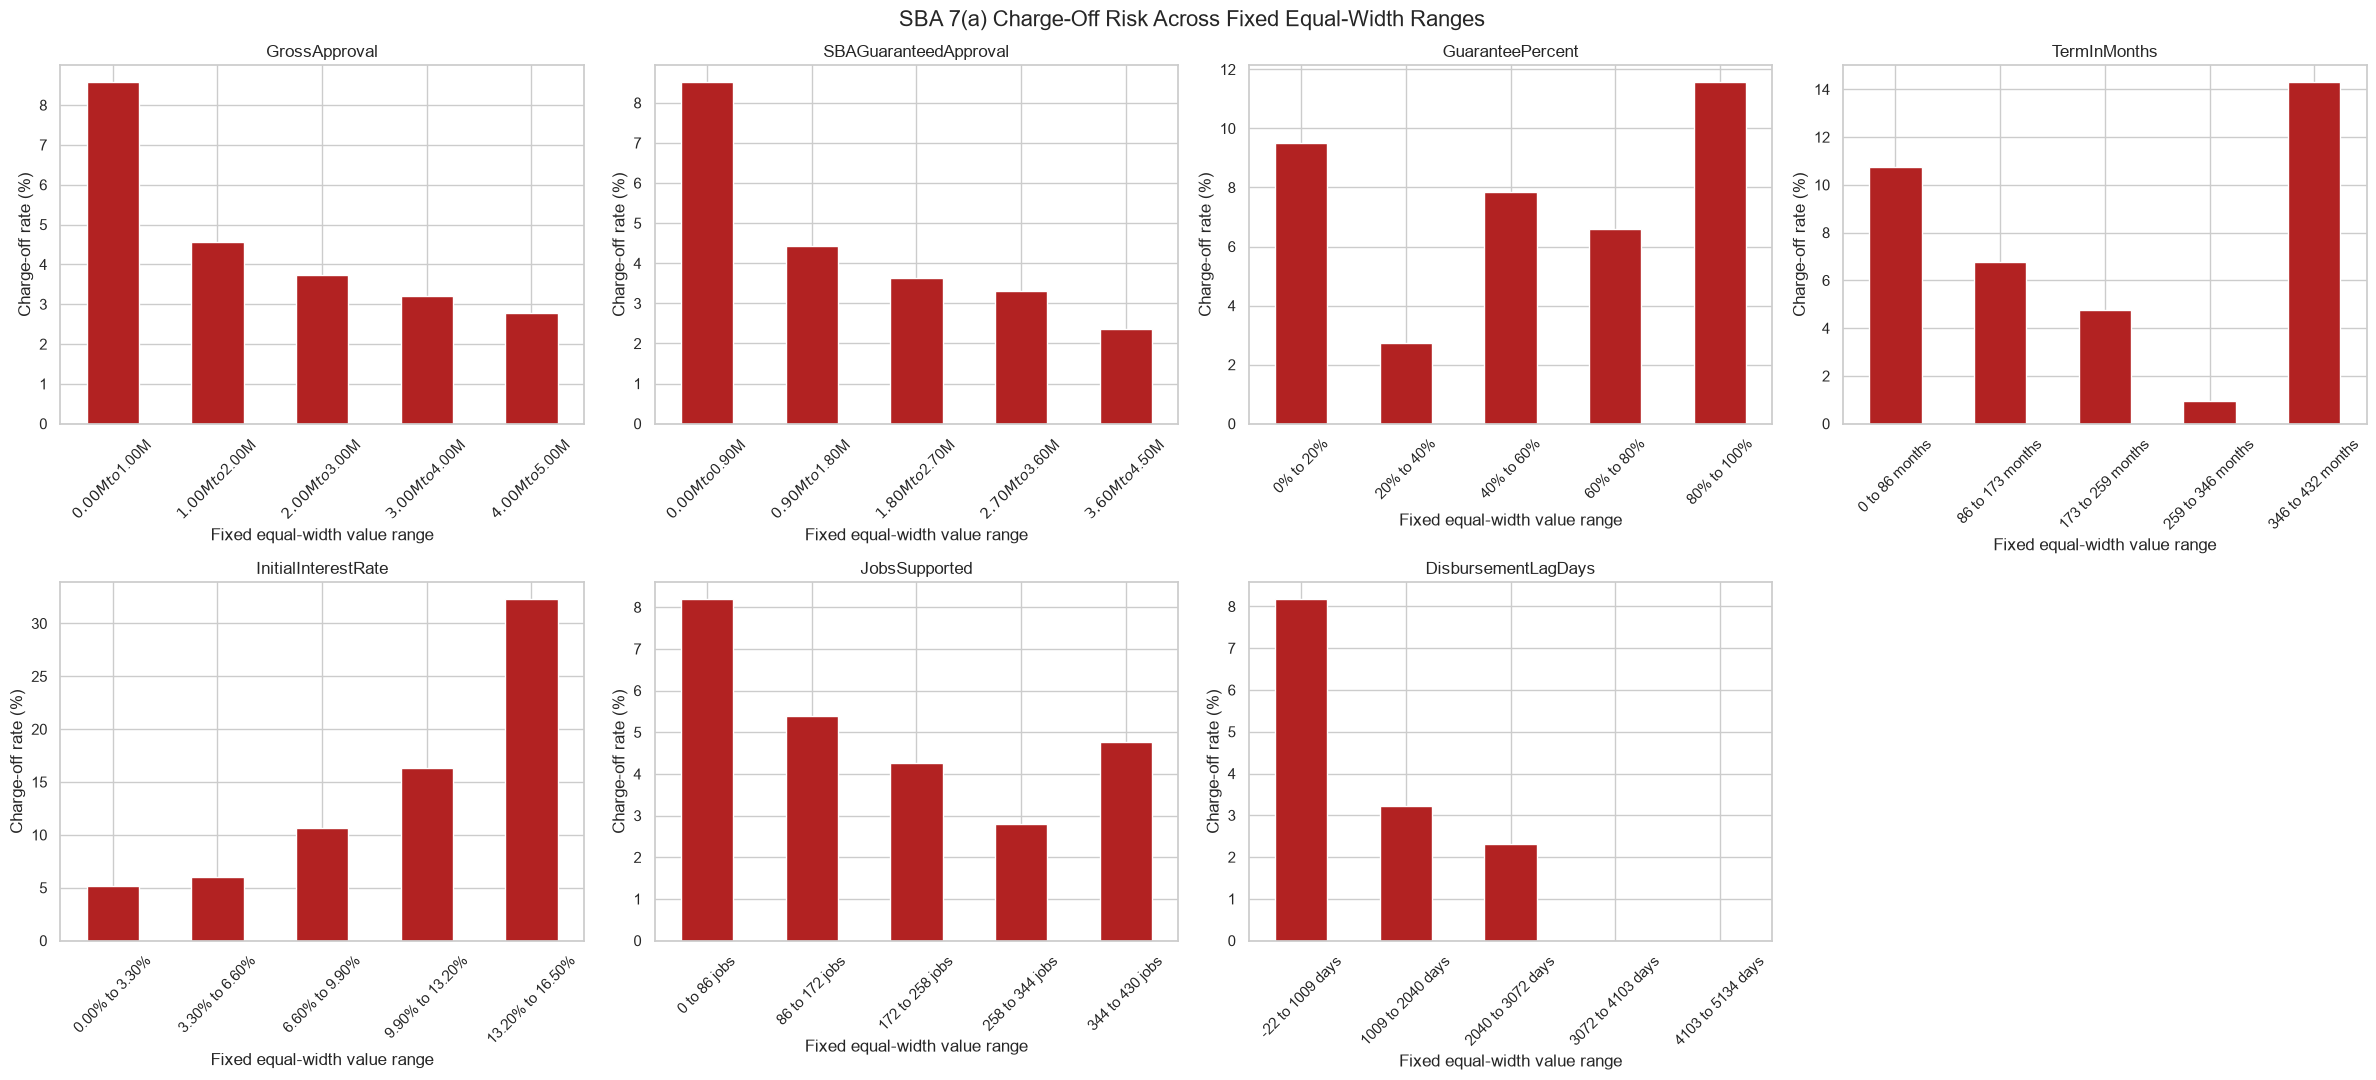

In [6]:
# 7(a) Loan Characteristics and Charge-Off Risk Analysis
# ChargeOff is the outcome; charge-off dates and amounts are excluded from predictors.

loan_characteristics_7alist = df7a[[
    "GrossApproval", "SBAGuaranteedApproval", "ApprovalDate", "ApprovalFY",
    "FirstDisbursementDate", "ProcessingMethod", "InitialInterestRate",
    "FixedorVariableInterestInd", "TermInMonths", "NaicsCode", "NaicsDescription",
    "FranchiseCode", "FranchiseName", "ProjectCounty", "ProjectState",
    "SBADistrictOffice", "CongressionalDistrict", "BusinessType", "BusinessAge",
    "RevolverStatus", "JobsSupported", "CollateralInd", "BankState", "LoanStatus"]].copy()

loan_characteristics_7a = pd.DataFrame(loan_characteristics_7alist)

numeric_columns_7a = [
    "GrossApproval", "SBAGuaranteedApproval", "TermInMonths",
    "InitialInterestRate", "NaicsCode", "FranchiseCode",
    "CongressionalDistrict", "JobsSupported", "ApprovalFY"
]
for column in numeric_columns_7a:
    if column in loan_characteristics_7a.columns: loan_characteristics_7a[column] = pd.to_numeric(loan_characteristics_7a[column], errors="coerce")

for column in ["ApprovalDate", "FirstDisbursementDate"]:
    if column in loan_characteristics_7a.columns: loan_characteristics_7a[column] = pd.to_datetime(loan_characteristics_7a[column], dayfirst=True, errors="coerce")

categorical_columns_7a = [
    "ProcessingMethod", "FixedorVariableInterestInd", "NaicsDescription",
    "ProjectState", "SBADistrictOffice", "BusinessType", "BusinessAge",
    "RevolverStatus", "CollateralInd", "BankState", "FranchiseName"
]

for column in categorical_columns_7a:
    loan_characteristics_7a[column] = (
        loan_characteristics_7a[column].fillna("Missing").astype(str).str.strip()
        .replace("", "Missing")
    )

loan_characteristics_7a["LoanStatus"] = (
    loan_characteristics_7a["LoanStatus"]
    .astype("string")
    .str.strip()
    .str.upper()
)

loan_characteristics_7a = loan_characteristics_7a[
    loan_characteristics_7a["LoanStatus"].isin(["P I F", "CHGOFF"])
].copy()

loan_characteristics_7a["ChargeOff"] = (loan_characteristics_7a["LoanStatus"] == "CHGOFF")
loan_characteristics_7a["GuaranteePercent"] = np.where(
    loan_characteristics_7a["GrossApproval"] > 0,
    loan_characteristics_7a["SBAGuaranteedApproval"]
    / loan_characteristics_7a["GrossApproval"] * 100,
    np.nan
)

loan_characteristics_7a["DisbursementLagDays"] = (
    loan_characteristics_7a["FirstDisbursementDate"]
    - loan_characteristics_7a["ApprovalDate"]
).dt.days

analysis_columns_7a = [
    "GrossApproval", "SBAGuaranteedApproval", "GuaranteePercent", "TermInMonths",
    "InitialInterestRate", "JobsSupported", "DisbursementLagDays"
]

print(f"Loans analyzed: {len(loan_characteristics_7a):,}")
print(f"Overall charge-off rate: {loan_characteristics_7a['ChargeOff'].mean() * 100:.2f}%")

status_summary_7a = (
    loan_characteristics_7a.groupby("ChargeOff")[analysis_columns_7a]
    .agg(["mean", "median"])
    .round(2)
)
status_summary_7a.index = ["Paid In Full", "Charged off"]
print("Numeric characteristics by loan outcome:")
display(status_summary_7a)

coverage_7a = pd.DataFrame({
    "Non_Missing": loan_characteristics_7a.notna().sum(),
    "Missing": loan_characteristics_7a.isna().sum(),
    "Missing_Percent": (
        loan_characteristics_7a.isna().mean() * 100
    ).round(2)
}).sort_values("Missing_Percent", ascending=False)
coverage_7a = coverage_7a[coverage_7a["Missing"] >=10]
print("Data coverage for candidate characteristics:")
display(coverage_7a)

fixed_ranges_7a = {
    "GrossApproval": (0, 5_000_000),
    "SBAGuaranteedApproval": (0, 4_500_000),
    "GuaranteePercent": (0, 100),
    "TermInMonths": (0, 432),
    "JobsSupported": (0, 430)
}


def format_range_label_7a(lower, upper, column):
    if column in ["GrossApproval", "SBAGuaranteedApproval"]:
        return f"${lower / 1_000_000:.2f}M to ${upper / 1_000_000:.2f}M"
    if column == "GuaranteePercent":
        return f"{lower:.0f}% to {upper:.0f}%"
    if column == "InitialInterestRate":
        return f"{lower:.2f}% to {upper:.2f}%"
    if column == "TermInMonths":
        return f"{lower:.0f} to {upper:.0f} months"
    if column == "JobsSupported":
        return f"{lower:.0f} to {upper:.0f} jobs"
    if column == "DisbursementLagDays":
        return f"{lower:.0f} to {upper:.0f} days"
    return f"{lower:,.2f} to {upper:,.2f}"


def risk_by_fixed_width_7a(data, column, label, groups=5):
    usable = data[[column, "ChargeOff"]].dropna().copy()
    minimum, maximum = fixed_ranges_7a.get(
        column, (usable[column].min(), usable[column].max())
    )
    bin_edges = np.linspace(minimum, maximum, groups + 1)
    bin_edges[-1] = np.nextafter(bin_edges[-1], np.inf)
    range_labels = [
        format_range_label_7a(bin_edges[position], bin_edges[position + 1], column)
        for position in range(groups)
    ]
    usable["Range"] = pd.cut(
        usable[column], bins=bin_edges, labels=range_labels, include_lowest=True
    )
    result = usable.groupby("Range", observed=False).agg(
        Total_Loans=("ChargeOff", "size"),
        Charge_Offs=("ChargeOff", "sum"),
        Charge_Off_Rate=("ChargeOff", "mean")
    )
    result["Charge_Off_Rate"] = (result["Charge_Off_Rate"] * 100).round(2)
    result.index.name = label
    return result

fixed_numeric_risk_tables_7a = {}
for column in analysis_columns_7a:
    fixed_numeric_risk_tables_7a[column] = risk_by_fixed_width_7a(
        loan_characteristics_7a, column, f"{column}_Range"
    )
    print(f"Charge-off risk by {column} fixed equal-width range:")
    display(fixed_numeric_risk_tables_7a[column])


def risk_by_category_7a(data, column, minimum_loans=50):
    result = data.groupby(column, dropna=False)["ChargeOff"].agg(
        Total_Loans="size", Charge_Offs="sum"
    )
    result["Charge_Off_Rate"] = (
        result["Charge_Offs"] / result["Total_Loans"] * 100
    ).round(2)
    return result[result["Total_Loans"] >= minimum_loans].sort_values(
        ["Charge_Off_Rate", "Total_Loans"], ascending=[False, False]
    )

categorical_risk_tables_7a = {}
for column in categorical_columns_7a:
    categorical_risk_tables_7a[column] = risk_by_category_7a(loan_characteristics_7a, column)
    print(f"{column}: charge-off rates for groups with at least 50 loans")
    display(categorical_risk_tables_7a[column].head(15))

fixed_variable_risk_7a = categorical_risk_tables_7a["FixedorVariableInterestInd"]
print("Charge-off risk by fixed versus variable interest rate:")
display(fixed_variable_risk_7a)

fig, axes = plt.subplots(2, 4, figsize=(24, 11))
for axis, column in zip(axes.flat, analysis_columns_7a):
    fixed_numeric_risk_tables_7a[column]["Charge_Off_Rate"].plot(
        kind="bar", ax=axis, color="firebrick"
    )
    axis.set_title(column)
    axis.set_xlabel("Fixed equal-width value range")
    axis.set_ylabel("Charge-off rate (%)")
    axis.tick_params(axis="x", rotation=45)
axes.flat[-1].axis("off")
fig.suptitle("SBA 7(a) Charge-Off Risk Across Fixed Equal-Width Ranges", fontsize=16)
plt.tight_layout()
plt.show()

Loans analyzed: 117983
Overall charge-off rate: 0.78%
Numeric characteristics by loan outcome:


GrossApproval           ThirdPartyDollars            \
                        mean    median              mean    median   
Paid or active     836201.33  520000.0        1142656.03  655732.5   
Charged off        754052.00  494000.0        1062942.31  632168.0   

               JobsSupported        TotalBorrowing             TermInMonths  \
                        mean median           mean      median         mean   
Paid or active         10.54    5.0     2070279.22  1242048.06       260.57   
Charged off            16.43    8.0     1900635.17  1174312.11       229.60   

                       
               median  
Paid or active  240.0  
Charged off     240.0

Data coverage for candidate characteristics:


,Non_Missing,Missing,Missing_Percent
FranchiseCode,5606,112377,95.25
FirstDisbursementDate,94903,23080,19.56
NaicsCode,117550,433,0.37
ThirdPartyDollars,117564,419,0.36
TotalBorrowing,117564,419,0.36


Charge-off risk by GrossApproval fixed equal-width range:


...

,Total_Loans,Charge_Offs,Charge_Off_Rate
BusinessAge,,,
Unanswered,7411,197,2.66
"New, Less than 1 Year old",359,7,1.95
Less than 4 years old but at least 3,48493,646,1.33
Less than 3 years old but at least 2,146,1,0.68
"Existing, 5 or more years",1898,12,0.63
New Business or 2 years or less,855,3,0.35
Change of Ownership,1419,3,0.21
"Startup, Loan Funds will Open Business",7838,10,0.13
Existing or more than 2 years old,48894,44,0.09


CollateralInd: charge-off rates for groups with at least 50 loans


,Total_Loans,Charge_Offs,Charge_Off_Rate
CollateralInd,,,
N,1834,63,3.44
Y,116149,860,0.74


FranchiseName: charge-off rates for groups with at least 50 loans


,Total_Loans,Charge_Offs,Charge_Off_Rate
FranchiseName,,,
CHOICE HOTELS INTERNATIONAL INC.,88,5,5.68
TEMPORARY FRANCHISES,520,23,4.42
DAIRY QUEEN,71,3,4.23
DAYS INN,81,3,3.70
COMFORT/ COMFORT INN & SUITES/ COMFORT SUITES,73,2,2.74
BEST WESTERN INN,131,3,2.29
HOLIDAY INN,132,3,2.27
LA QUINTA INN,71,1,1.41
Hampton Inn by Hilton,86,1,1.16


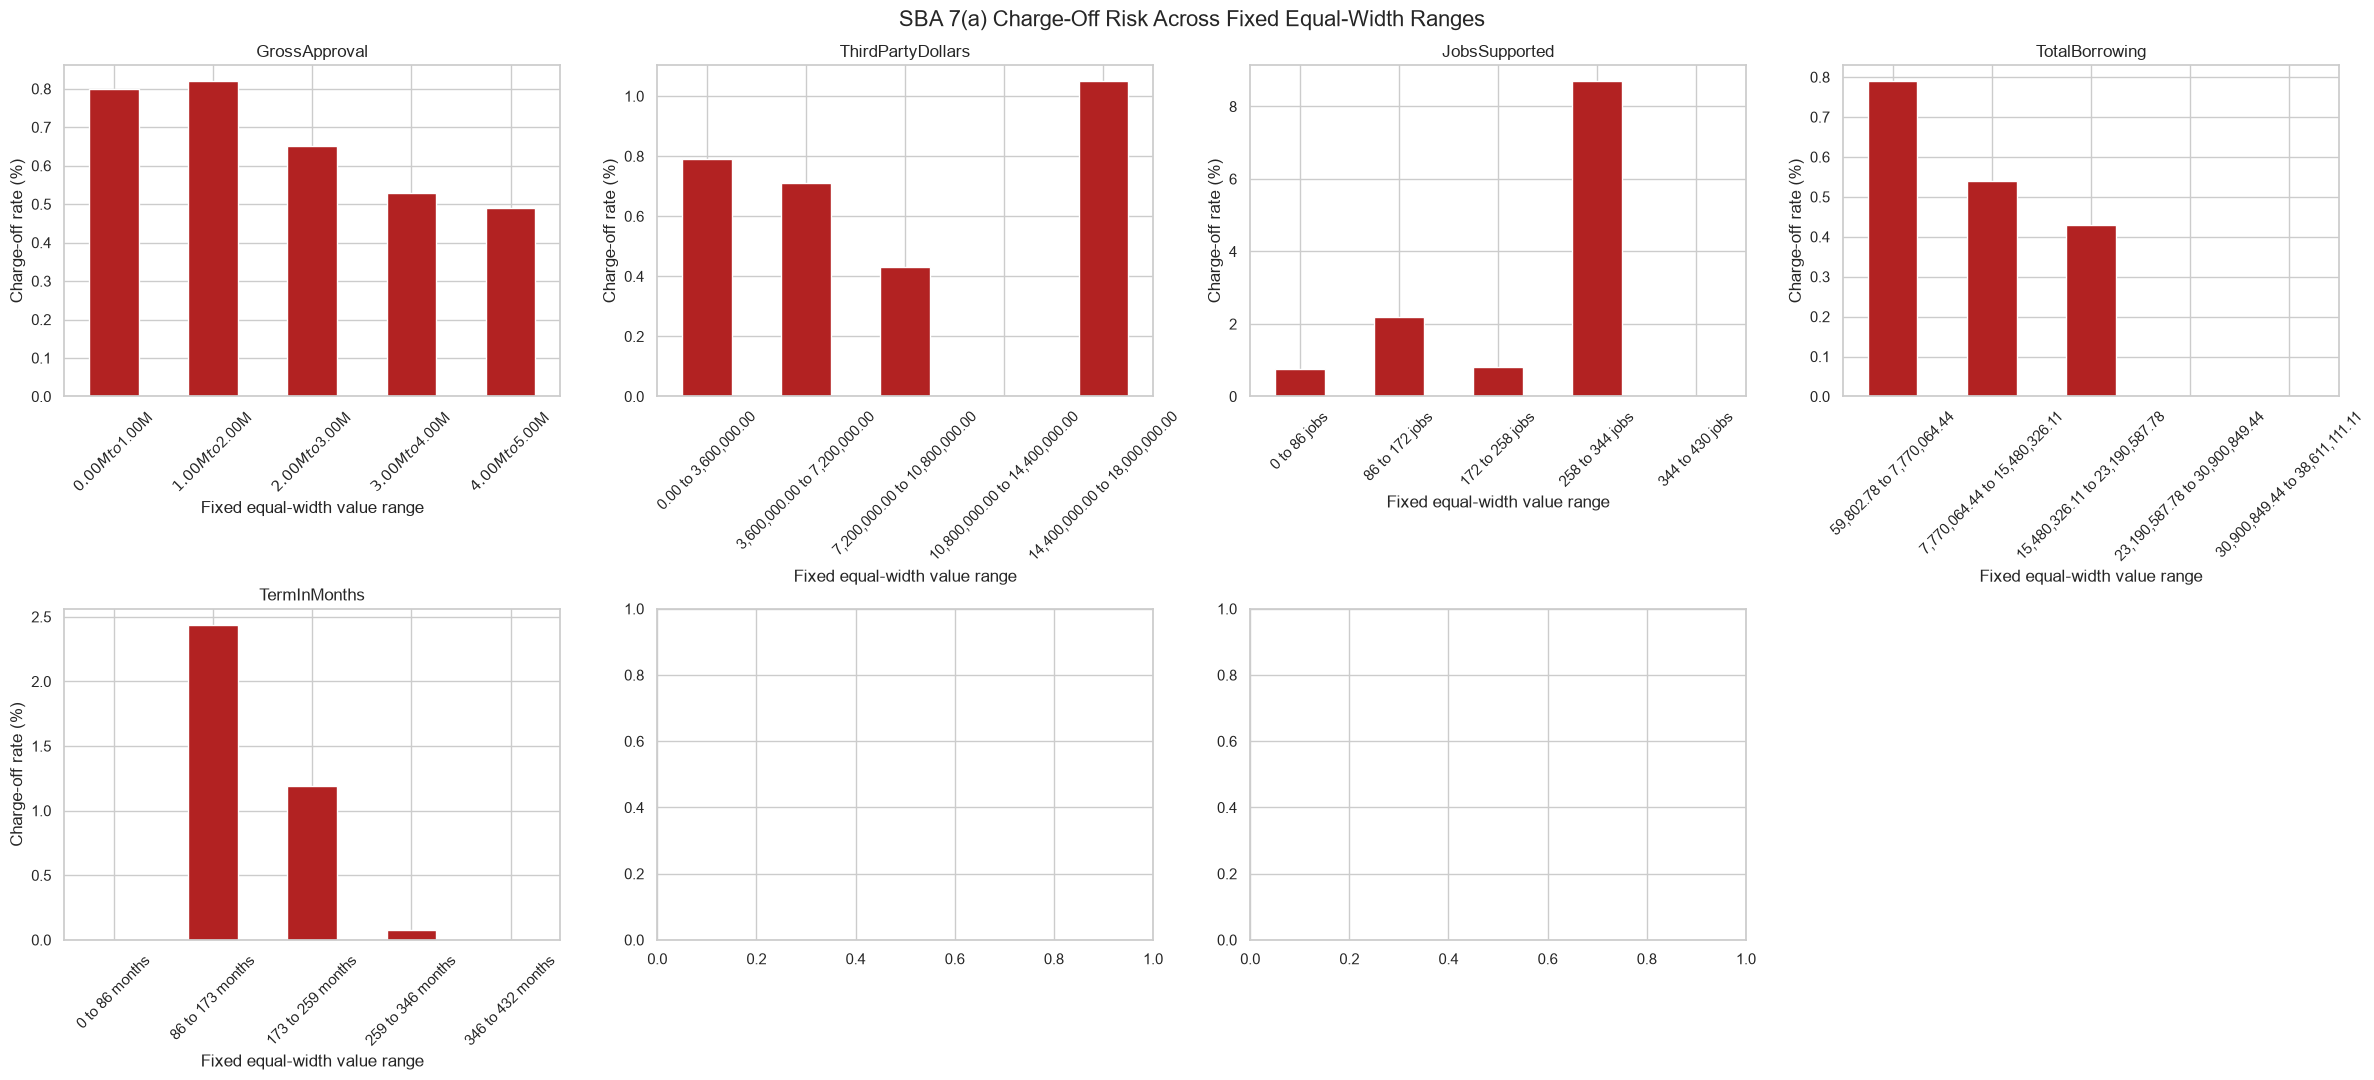

In [8]:
# 504 Loans Characteristics Analysis
loan_characteristics_504list = df504[[
    "GrossApproval", "ApprovalDate", "ApprovalFY",
        "FirstDisbursementDate", "ProcessingMethod", "TermInMonths", "NaicsCode", 
        "ThirdPartyDollars", "NaicsDescription",
        "FranchiseCode", "FranchiseName", "ProjectCounty", "ProjectState",
        "SBADistrictOffice", "CongressionalDistrict", "BusinessType", "BusinessAge",
        "JobsSupported", "CollateralInd", "LoanStatus"]].copy()

loan_characteristics_504 = pd.DataFrame(loan_characteristics_504list)

numeric_columns_504 = [
    "GrossApproval", "TermInMonths", "NaicsCode", "FranchiseCode",
    "CongressionalDistrict", "JobsSupported", "ApprovalFY"
]
for column in numeric_columns_504:
    if column in loan_characteristics_504.columns: 
        loan_characteristics_504[column] = pd.to_numeric(loan_characteristics_504[column], errors="coerce"
)
for column in ["ApprovalDate", "FirstDisbursementDate"]:
    if column in loan_characteristics_504.columns: 
        loan_characteristics_504[column] = pd.to_datetime(loan_characteristics_504[column], dayfirst=True, errors="coerce"
)

categorical_columns_504 = [
    "ProcessingMethod", "NaicsDescription","SBADistrictOffice",
    "ProjectState", "BusinessType", "BusinessAge",
    "CollateralInd", "FranchiseName"
]

for column in categorical_columns_504:
    loan_characteristics_504[column] = (
        loan_characteristics_504[column].fillna("Missing").astype(str).str.strip()
        .replace("", "Missing")
    )

loan_characteristics_504["ChargeOff"] = loan_characteristics_504["LoanStatus"].eq("CHGOFF")
loan_characteristics_504["TotalBorrowing"] = np.where(
    loan_characteristics_504["ThirdPartyDollars"].isna() | loan_characteristics_504["GrossApproval"].isna(),
    np.nan,
    loan_characteristics_504["ThirdPartyDollars"] + loan_characteristics_504["GrossApproval"] * (100/90)
)
analysis_columns_504 = [
    "GrossApproval", "ThirdPartyDollars",
    "JobsSupported", "TotalBorrowing", "TermInMonths"
]

print(f"Loans analyzed: {len(loan_characteristics_504):}")
print(f"Overall charge-off rate: {loan_characteristics_504['ChargeOff'].mean() * 100:.2f}%")

status_summary_504 = (
    loan_characteristics_504.groupby("ChargeOff")[analysis_columns_504]
    .agg(["mean", "median"])
    .round(2)
)
status_summary_504.index = ["Paid or active", "Charged off"]
print("Numeric characteristics by loan outcome:")
display(status_summary_504)

status_summary = (
    loan_characteristics_504.groupby("ChargeOff")[[
        "GrossApproval",
        "TermInMonths",
        "JobsSupported"
    ]]
    .agg(["count", "mean", "median"])
    .round(2)
)

coverage_504 = pd.DataFrame({
    "Non_Missing": loan_characteristics_504.notna().sum(),
    "Missing": loan_characteristics_504.isna().sum(),
    "Missing_Percent": (
        loan_characteristics_504.isna().mean() * 100
    ).round(2)
}).sort_values("Missing_Percent", ascending=False)
coverage_504 = coverage_504[coverage_504["Missing"] >=10]
print("Data coverage for candidate characteristics:")
display(coverage_504)

fixed_ranges_504 = {
    "GrossApproval": (0, 5_000_000),
    "ThirdPartyDollars": (0,  18_000_000),
    "SBAGuaranteedApproval": (0, 4_500_000),
    "GuaranteePercent": (0, 100),
    "TermInMonths": (0, 432),
    "JobsSupported": (0, 430)
}

def format_range_label_504(lower, upper, column):
    if column in ["GrossApproval", "ThirdPartyDollars"]:
        return f"${lower / 1_000_000:.2f}M to ${upper / 1_000_000:.2f}M"
    if column == "GuaranteePercent":
        return f"{lower:.0f}% to {upper:.0f}%"
    if column == "InitialInterestRate":
        return f"{lower:.2f}% to {upper:.2f}%"
    if column == "TermInMonths":
        return f"{lower:.0f} to {upper:.0f} months"
    if column == "JobsSupported":
        return f"{lower:.0f} to {upper:.0f} jobs"
    if column == "DisbursementLagDays":
        return f"{lower:.0f} to {upper:.0f} days"
    return f"{lower:,.2f} to {upper:,.2f}"


def risk_by_fixed_width_504(data, column, label, groups=5):
    usable = data[[column, "ChargeOff"]].dropna().copy()
    minimum, maximum = fixed_ranges_504.get(
        column, (usable[column].min(), usable[column].max())
    )
    bin_edges = np.linspace(minimum, maximum, groups + 1)
    bin_edges[-1] = np.nextafter(bin_edges[-1], np.inf)
    range_labels = [
        format_range_label_7a(bin_edges[position], bin_edges[position + 1], column)
        for position in range(groups)
    ]
    usable["Range"] = pd.cut(
        usable[column], bins=bin_edges, labels=range_labels, include_lowest=True
    )
    result = usable.groupby("Range", observed=False).agg(
        Total_Loans=("ChargeOff", "size"),
        Charge_Offs=("ChargeOff", "sum"),
        Charge_Off_Rate=("ChargeOff", "mean")
    )
    result["Charge_Off_Rate"] = (result["Charge_Off_Rate"] * 100).round(2)
    result.index.name = label
    return result

fixed_numeric_risk_tables_504 = {}
for column in analysis_columns_504:
    fixed_numeric_risk_tables_504[column] = risk_by_fixed_width_504(
        loan_characteristics_504, column, f"{column}_Range"
    )
    print(f"Charge-off risk by {column} fixed equal-width range:")
    display(fixed_numeric_risk_tables_504[column])


def risk_by_category_504(data, column, minimum_loans=50):
    result = data.groupby(column, dropna=False)["ChargeOff"].agg(
        Total_Loans="size", Charge_Offs="sum"
    )
    result["Charge_Off_Rate"] = (
        result["Charge_Offs"] / result["Total_Loans"] * 100
    ).round(2)
    return result[result["Total_Loans"] >= minimum_loans].sort_values(
        ["Charge_Off_Rate", "Total_Loans"], ascending=[False, False]
    )

categorical_risk_tables_504 = {}
for column in categorical_columns_504:
    categorical_risk_tables_504[column] = risk_by_category_504(loan_characteristics_504, column)
    print(f"{column}: charge-off rates for groups with at least 50 loans")
    display(categorical_risk_tables_504[column].head(15))


fig, axes = plt.subplots(2, 4, figsize=(24, 11))
for axis, column in zip(axes.flat, analysis_columns_504):
    fixed_numeric_risk_tables_504[column]["Charge_Off_Rate"].plot(
        kind="bar", ax=axis, color="firebrick"
    )
    axis.set_title(column)
    axis.set_xlabel("Fixed equal-width value range")
    axis.set_ylabel("Charge-off rate (%)")
    axis.tick_params(axis="x", rotation=45)
axes.flat[-1].axis("off")
fig.suptitle("SBA 7(a) Charge-Off Risk Across Fixed Equal-Width Ranges", fontsize=16)
plt.tight_layout()
plt.show()

3. Geographic Risk:
How does credit risk vary across geographic markets, and what geographic patterns emerge in SBA lending?

States with the highest charge-off rates:


,Total_Loans,Charge_Offs,Charge_Off_Rate
BankState,,,
DC,309,39,12.62
RI,9870,999,10.12
DE,57584,4622,8.03
TX,24526,1826,7.45
SD,63363,3993,6.30
UT,35166,2061,5.86
HI,3502,189,5.40
OR,11684,620,5.31
AR,14158,738,5.21


SBA districts with the highest charge-off rates:


,Total_Loans,Charge_Offs,Charge_Off_Rate
SBADistrictOffice,,,
NEW YORK DISTRICT OFFICE,38622,2539,6.57
HOUSTON DISTRICT OFFICE,21257,1310,6.16
SOUTH FLORIDA DISTRICT OFFICE,39995,2436,6.09
EL PASO DISTRICT OFFICE,1703,103,6.05
LOWER RIO GRANDE VALLEY DISTRICT OFFICE,2488,145,5.83
...,...,...,...
MAINE DISTRICT OFFICE,5372,155,2.89
PITTSBURGH DISTRICT OFFICE,8738,244,2.79
MONTANA DISTRICT OFFICE,4363,114,2.61


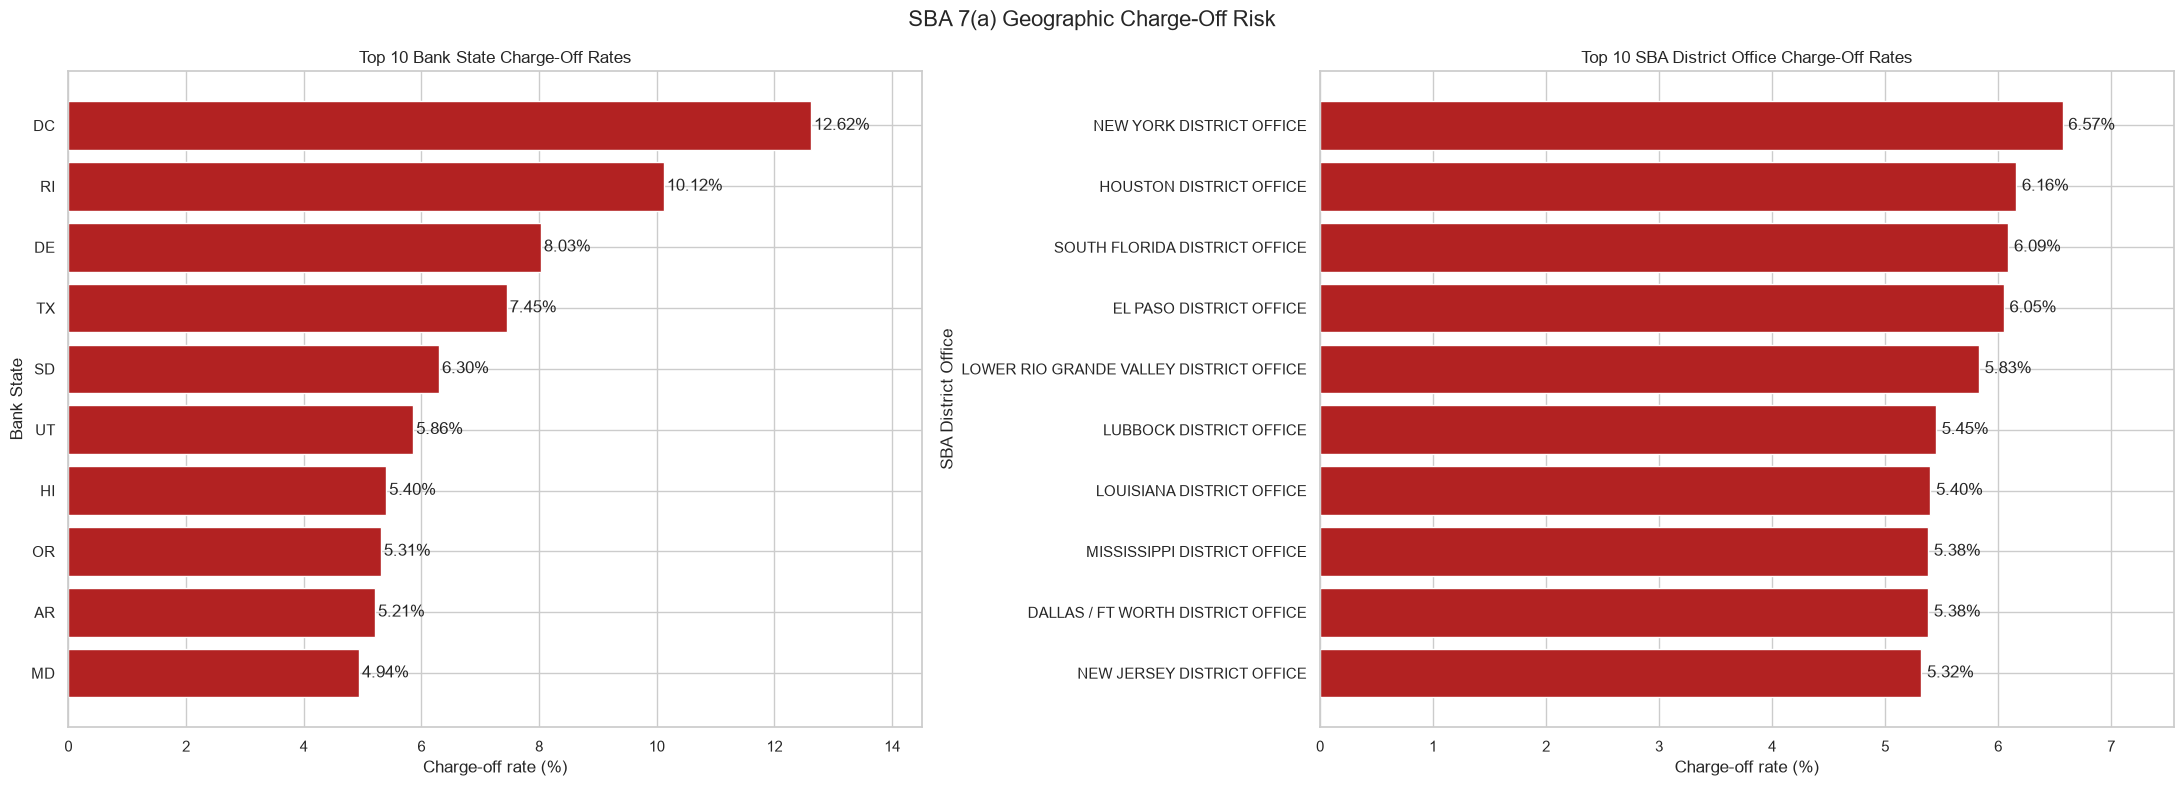

In [9]:
# 7(a) Geographic Risk Analysis
Charge_Off = ["CHGOFF"]

us_states_and_recognised_territories = [
    "AL", "AK", "AZ", "AR", "CA", "CO", "CT", "DE", "FL", "GA",
    "HI", "ID", "IL", "IN", "IA", "KS", "KY", "LA", "ME", "MD",
    "MA", "MI", "MN", "MS", "MO", "MT", "NE", "NV", "NH", "NJ",
    "NM", "NY", "NC", "ND", "OH", "OK", "OR", "PA", "RI", "SC",
    "SD", "TN", "TX", "UT", "VT", "VA", "WA", "WV", "WI", "WY",
    "DC", "AS", "GU", "MP", "PR", "VI"
]


def charge_off_rates(data, group_column, minimum_loans=50):
    grouped = data.dropna(subset=[group_column]).groupby(group_column)
    rates = grouped["LoanStatus"].agg(
        Total_Loans="size",
        Charge_Offs=lambda status: status.eq("CHGOFF").sum()
    )
    rates["Charge_Off_Rate"] = (
        rates["Charge_Offs"] / rates["Total_Loans"] * 100
    ).round(2)
    return rates[rates["Total_Loans"] >= minimum_loans].sort_values(
        "Charge_Off_Rate", ascending=False
    )

state_data = df7a[df7a["BankState"].isin(us_states_and_recognised_territories)]
state_charge_off_rates_7a = charge_off_rates(state_data, "BankState")
district_charge_off_rates_7a = charge_off_rates(df7a, "SBADistrictOffice")

print("States with the highest charge-off rates:")
display(state_charge_off_rates_7a)
print("SBA districts with the highest charge-off rates:")
display(district_charge_off_rates_7a)

# Plot the ten highest-risk groups with at least 50 loans.
fig, axes = plt.subplots(1, 2, figsize=(22, 8))
for axis, table, title in zip(
    axes,
    [state_charge_off_rates_7a, district_charge_off_rates_7a],
    ["Bank State", "SBA District Office"]
):
    graph_data = table.head(10).sort_values("Charge_Off_Rate")
    axis.barh(
        graph_data.index.astype(str),
        graph_data["Charge_Off_Rate"],
        color="firebrick"
    )
    axis.set_title(f"Top 10 {title} Charge-Off Rates")
    axis.set_xlabel("Charge-off rate (%)")
    axis.set_ylabel(title)
    axis.set_xlim(0, graph_data["Charge_Off_Rate"].max() * 1.15)
    for position, rate in enumerate(graph_data["Charge_Off_Rate"]):
        axis.text(rate + 0.05, position, f"{rate:.2f}%", va="center")

fig.suptitle("SBA 7(a) Geographic Charge-Off Risk", fontsize=16)
plt.tight_layout()
plt.show()

States with the highest charge-off rates:


,Total_Loans,Charge_Offs,Charge_Off_Rate
CDC_State,,,
AR,151,5,3.31
PR,1061,34,3.20
MD,236,7,2.97
KY,450,12,2.67
MS,115,3,2.61
AL,886,19,2.14
PA,1500,31,2.07
ME,150,3,2.00
DC,1922,38,1.98


SBA districts with the highest charge-off rates:


,Total_Loans,Charge_Offs,Charge_Off_Rate
SBADistrictOffice,,,
LOWER RIO GRANDE VALLEY DISTRICT OFFICE,183,7,3.83
ARKANSAS DISTRICT OFFICE,288,10,3.47
PUERTO RICO AND USVI DISTRICT OFFICE,1061,34,3.20
MISSISSIPPI DISTRICT OFFICE,133,4,3.01
SYRACUSE DISTRICT OFFICE,873,24,2.75
...,...,...,...
SANTA ANA DISTRICT OFFICE,4885,11,0.23
SACRAMENTO DISTRICT OFFICE,2287,5,0.22
SAN FRANCISCO DISTRICT OFFICE,4701,10,0.21


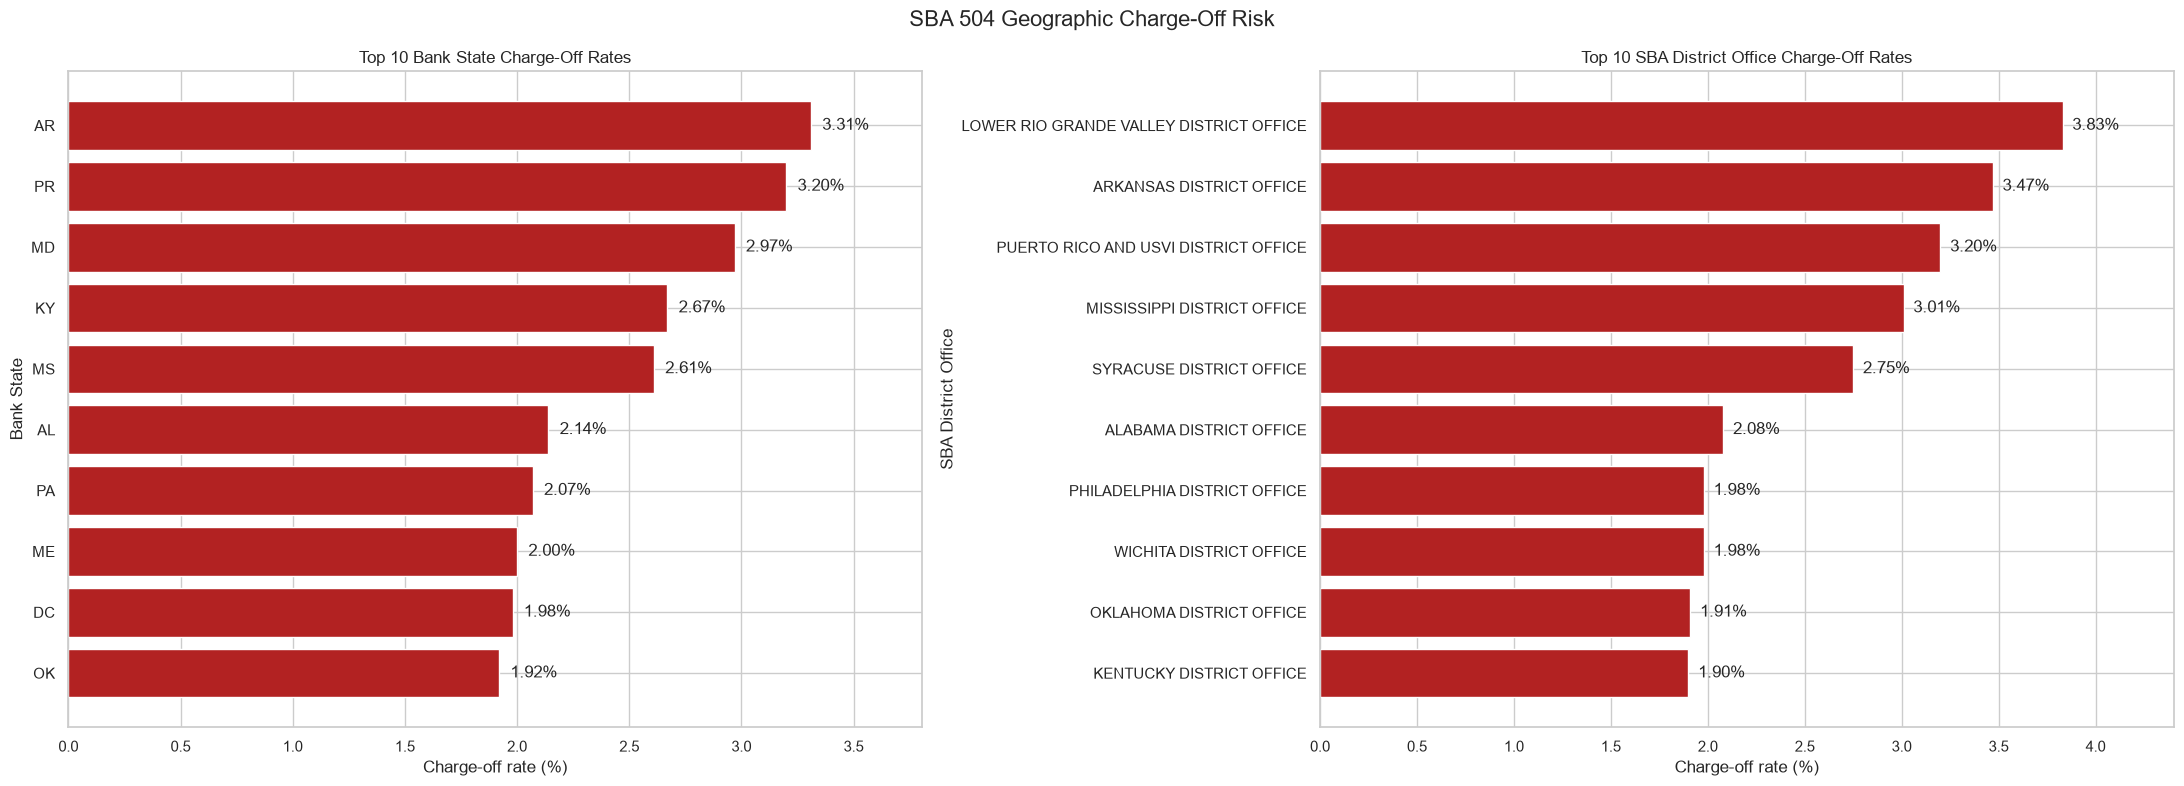

In [10]:
# 504 Geographic Risk Analysis
Charge_Off = ["CHGOFF"]

us_states_and_recognised_territories = [
    "AL", "AK", "AZ", "AR", "CA", "CO", "CT", "DE", "FL", "GA",
    "HI", "ID", "IL", "IN", "IA", "KS", "KY", "LA", "ME", "MD",
    "MA", "MI", "MN", "MS", "MO", "MT", "NE", "NV", "NH", "NJ",
    "NM", "NY", "NC", "ND", "OH", "OK", "OR", "PA", "RI", "SC",
    "SD", "TN", "TX", "UT", "VT", "VA", "WA", "WV", "WI", "WY",
    "DC", "AS", "GU", "MP", "PR", "VI"
]


def charge_off_rates(data, group_column, minimum_loans=50):
    grouped = data.dropna(subset=[group_column]).groupby(group_column)
    rates = grouped["LoanStatus"].agg(
        Total_Loans="size",
        Charge_Offs=lambda status: status.eq("CHGOFF").sum()
    )
    rates["Charge_Off_Rate"] = (
        rates["Charge_Offs"] / rates["Total_Loans"] * 100
    ).round(2)
    return rates[rates["Total_Loans"] >= minimum_loans].sort_values(
        "Charge_Off_Rate", ascending=False
    )

state_data = df504[df504["CDC_State"].isin(us_states_and_recognised_territories)]
state_charge_off_rates_504 = charge_off_rates(state_data, "CDC_State")
district_charge_off_rates_504 = charge_off_rates(df504, "SBADistrictOffice")

print("States with the highest charge-off rates:")
display(state_charge_off_rates_504)
print("SBA districts with the highest charge-off rates:")
display(district_charge_off_rates_504)

# Plot the ten highest-risk groups with at least 50 loans.
fig, axes = plt.subplots(1, 2, figsize=(22, 8))
for axis, table, title in zip(
    axes,
    [state_charge_off_rates_504, district_charge_off_rates_504],
    ["Bank State", "SBA District Office"]
):
    graph_data = table.head(10).sort_values("Charge_Off_Rate")
    axis.barh(
        graph_data.index.astype(str),
        graph_data["Charge_Off_Rate"],
        color="firebrick"
    )
    axis.set_title(f"Top 10 {title} Charge-Off Rates")
    axis.set_xlabel("Charge-off rate (%)")
    axis.set_ylabel(title)
    axis.set_xlim(0, graph_data["Charge_Off_Rate"].max() * 1.15)
    for position, rate in enumerate(graph_data["Charge_Off_Rate"]):
        axis.text(rate + 0.05, position, f"{rate:.2f}%", va="center")

fig.suptitle("SBA 504 Geographic Charge-Off Risk", fontsize=16)
plt.tight_layout()
plt.show()

4. Hypothesis Testing:
Do charged-off and non-charged-off SBA loans differ significantly in financing amount and repayment characteristics?
7(a):
Loan amount → charged-off vs non-charged-off
Loan term → charged-off vs non-charged-off
Potentially interest rate → charged-off vs non-charged-off
504:
SBA/CDC financing amount → charged-off vs non-charged-off
Third-party financing amount → charged-off vs non-charged-off
Project/financing characteristics → charged-off vs non-charged-off

In [11]:
df504_months = df504.copy()
 
df504_months["IsChargedOff"] = (df504_months["LoanStatus"] == "CHGOFF").astype(int)

small_array_504 = df504_months[df504_months["TermInMonths"] == 120]["IsChargedOff"].to_numpy()
mid_array_504 = df504_months[df504_months["TermInMonths"] == 240]["IsChargedOff"].to_numpy()
large_array_504 = df504_months[df504_months["TermInMonths"] == 300]["IsChargedOff"].to_numpy()

n_short_504 = len(small_array_504)
n_mid_504 = len(mid_array_504)
n_large_504 = len(large_array_504)
n_bootstraps_504 = 10000

boot_diffs_504 = np.empty(n_bootstraps_504)

np.random.seed(42)

for i in range(n_bootstraps_504):
    boot_small_504 = np.random.choice(small_array_504, size=n_short_504, replace=True)
    p1_boot_504 = boot_small_504.mean()

    boot_mid_504 = np.random.choice(mid_array_504, size=n_mid_504, replace=True)
    p2_boot_504 = boot_mid_504.mean()

    boot_large_504 = np.random.choice(large_array_504, size=n_large_504, replace=True)
    p3_boot_504 = boot_mid_504.mean()

    boot_diffs_504[i] = p1_boot_504 - p2_boot_504 - p3_boot_504

boot_se = np.std(boot_diffs_504, ddof=1)
conf_int = np.percentile(boot_diffs_504, [2.5, 97.5])
observed_diff = small_array_504.mean() - mid_array_504.mean() - large_array_504.mean()

print(f"Observed Difference: {observed_diff:.4%}")
print(f"Bootstrap Standard Error: {boot_se:.4%}")
print(f"95% Confidence Interval for Difference: [{conf_int[0]:.4%}, {conf_int[1]:.4%}]")

Observed Difference: 1.1708%
Bootstrap Standard Error: 0.2562%
95% Confidence Interval for Difference: [-0.4227%, 0.5785%]


In [12]:
## 7(a)
# 1. Ensure your binary groups are isolated as clean NumPy arrays for speed
# (Make sure 'LoanStatus' == 'CHGOFF' matches your exact column details)
df7a_500m_less = df7a[df7a["TermInMonths"] < 500].copy()
df7a_500m_less["IsChargedOff"] = (df7a_500m_less["LoanStatus"] == "CHGOFF").astype(int)
mean_Terms = df7a_500m_less["TermInMonths"].mean()

# Extract binary arrays for short-term and long-term loans
short_array_7a = df7a_500m_less[df7a_500m_less["TermInMonths"] <= 128]["IsChargedOff"].to_numpy()
long_array_7a = df7a_500m_less[df7a_500m_less["TermInMonths"] > 128]["IsChargedOff"].to_numpy()

n_short_7a = len(short_array_7a)
n_long_7a = len(long_array_7a)
n_bootstraps_7a = 10000

# Pre-allocate an array to store the differences between proportions
boot_diffs_7a = np.empty(n_bootstraps_7a)

np.random.seed(42)  # Ensures reproducible results

# 2. Sequential Bootstrap Loop
for i in range(n_bootstraps_7a):
    # Resample short-term loans with replacement and find its rate
    boot_short_7a = np.random.choice(short_array_7a, size=n_short_7a, replace=True)
    p1_boot_7a = boot_short_7a.mean()
    
    # Resample long-term loans with replacement and find its rate
    boot_long_7a = np.random.choice(long_array_7a, size=n_long_7a, replace=True)
    p2_boot_7a = boot_long_7a.mean()
    
    # Store the difference (Short-Term Rate - Long-Term Rate)
    boot_diffs_7a[i] = p1_boot_7a - p2_boot_7a

# 3. Calculate statistics from the distribution
boot_se = np.std(boot_diffs_7a, ddof=1)
conf_int = np.percentile(boot_diffs_7a, [2.5, 97.5])
observed_diff = short_array_7a.mean() - long_array_7a.mean()

print(f"Observed Difference: {observed_diff:.4%}")
print(f"Bootstrap Standard Error: {boot_se:.4%}")
print(f"95% Confidence Interval for Difference: [{conf_int[0]:.4%}, {conf_int[1]:.4%}]")


Observed Difference: 3.9726%
Bootstrap Standard Error: 0.0361%
95% Confidence Interval for Difference: [3.9020%, 4.0436%]


In [13]:
# 1. Clean data and define your binary Charge-Off column
# (Make sure to replace 'LoanStatus' and 'CHGOFF' with your exact column details)
df7a_clean = df7a[df7a["TermInMonths"] < 500].copy()
df7a_clean["IsChargedOff"] = (df7a_clean["LoanStatus"] == "CHGOFF").astype(int) 

# 2. Split into Short-Term (<= 120 months) and Long-Term (> 120 months)
short_term_df = df7a_clean[df7a_clean["TermInMonths"] <= 120]
long_term_df = df7a_clean[df7a_clean["TermInMonths"] > 120]

# 3. Calculate baseline counts and sample sizes
x1 = short_term_df["IsChargedOff"].sum()  # Short-term defaults
n1 = len(short_term_df)                   # Short-term total
x2 = long_term_df["IsChargedOff"].sum()   # Long-term defaults
n2 = len(long_term_df)                    # Long-term total

# Calculate individual rates
p1 = x1 / n1
p2 = x2 / n2

print(f"Short-Term Charge-Off Rate: {p1:.2%}")
print(f"Long-Term Charge-Off Rate: {p2:.2%}")

# 4. Two-Sample Z-Test for Proportions Math
# Calculate pooled proportion
p_pooled = (x1 + x2) / (n1 + n2)

# Calculate standard error for proportions
se_pooled = np.sqrt(p_pooled * (1 - p_pooled) * (1/n1 + 1/n2))

# Calculate Z-statistic
z_stat = (p1 - p2) / se_pooled

# Calculate two-tailed p-value
p_val = 2 * norm.sf(abs(z_stat))

print(f"\nZ-statistic: {z_stat:.2f}")
print(f"P-value: {p_val}")

alpha = 0.05
if p_val <= alpha:
    print("Reject the null hypothesis: The charge-off rates are significantly different.")
else:
    print("Fail to reject the null hypothesis: No significant difference in charge-off rates.")


Short-Term Charge-Off Rate: 5.29%
Long-Term Charge-Off Rate: 1.11%

Z-statistic: 80.66
P-value: 0.0
Reject the null hypothesis: The charge-off rates are significantly different.


In [14]:
df7a_clean = df7a[df7a["TermInMonths"] < 500].copy()
df7a_clean["IsChargedOff"] = (df7a_clean["LoanStatus"] == "CHGOFF").astype(int) 

# 2. Split into Short-Term (<= 120 months) and Long-Term (> 120 months)
short_term_df7a = df7a_clean[df7a_clean["TermInMonths"] <= 120]
long_term_df7a = df7a_clean[df7a_clean["TermInMonths"] > 120]

t_test, p_val = stats.ttest_ind(short_term_df7a["IsChargedOff"], long_term_df7a["IsChargedOff"], equal_var=True)
print(f"t-statistic: {t_test:.4f}, p-value: {p_val:.4f}")

welch_t_stat, welch_p_val = stats.ttest_ind(short_term_df7a["IsChargedOff"], long_term_df7a["IsChargedOff"], equal_var=False)
print(f"t-statistic: {welch_t_stat:.4f}, p-value: {welch_p_val:.4f}")

t-statistic: 80.9438, p-value: 0.0000
t-statistic: 118.8023, p-value: 0.0000


In [15]:

df504_months = df504.copy()
 
df504_months["IsChargedOff"] = (df504_months["LoanStatus"] == "CHGOFF").astype(int)

g1 = df504_months[df504_months["TermInMonths"] == 120]["IsChargedOff"].to_numpy()
g2 = df504_months[df504_months["TermInMonths"] == 240]["IsChargedOff"].to_numpy()
g3 = df504_months[df504_months["TermInMonths"] == 300]["IsChargedOff"].to_numpy()

_, tp12 = stats.ttest_ind(g1, g2, equal_var=True)
_, tp23 = stats.ttest_ind(g2, g3, equal_var=True)
_, tp13 = stats.ttest_ind(g1, g3, equal_var=True)

_, wp12 = stats.ttest_ind(g1, g2, equal_var=False)
_, wp23 = stats.ttest_ind(g2, g3, equal_var=False)
_, wp13 = stats.ttest_ind(g1, g3, equal_var=False)

raw_p_values_nt = [tp12, tp23, tp13]
raw_p_values_wt = [wp12, wp23, wp13]
comparisons = ["Short vs Medium", "Medium vs Long", "Short vs Long"]


# Alternative pure-python adjustment: multiply by 3 comparisons (maxed out at 1.0)
adjusted_p_vals_nt = [min(p * 3, 1.0) for p in raw_p_values_nt]
reject_nt = [p < 0.05 for p in adjusted_p_vals_nt]

adjusted_p_vals_wt = [min(p * 3, 1.0) for p in raw_p_values_wt]
reject_wt = [p < 0.05 for p in adjusted_p_vals_wt]

results_df504_nt = pd.DataFrame({
    "Comparison": comparisons,
    "Raw P-Value": raw_p_values_nt,
    "Adjusted P-Value": adjusted_p_vals_nt,
    "Significant Change?": reject_nt
})
results_df504_wt = pd.DataFrame({
    "Comparison": comparisons,
    "Raw P-Value": raw_p_values_wt,
    "Adjusted P-Value": adjusted_p_vals_wt,
    "Significant Change?": reject_wt
})
print(results_df504_nt.to_string(index=False))
print(results_df504_wt.to_string(index=False))

     Comparison   Raw P-Value  Adjusted P-Value  Significant Change?
Short vs Medium  3.298679e-12      9.896036e-12                 True
 Medium vs Long 1.146475e-105     3.439424e-105                 True
  Short vs Long 1.928806e-174     5.786419e-174                 True
     Comparison   Raw P-Value  Adjusted P-Value  Significant Change?
Short vs Medium  3.293641e-07      9.880922e-07                 True
 Medium vs Long 1.638090e-137     4.914271e-137                 True
  Short vs Long  2.774759e-22      8.324277e-22                 True


In [16]:
df7a_clean = df7a[df7a["TermInMonths"] < 500].copy().reset_index(drop=True)
df7a_clean["IsChargedOff"] = (df7a_clean["LoanStatus"] == "CHGOFF").astype(int)

df7a_clean["TermGroup"] = pd.cut(
    df7a_clean["TermInMonths"],
    bins=[0, 120, 240, 500],
    labels=["Short (<=120)", "Medium (121-240)", "Long(>240)"]
)

table_7a = pd.crosstab(df7a_clean["TermGroup"], df7a_clean["IsChargedOff"])
print("--- Contingency Table for df7a ---")
print(table_7a)

chi2_7a, p_7a, dof_7a, expected_7a = stats.chi2_contingency(table_7a)

print(f"\nChi-Square Statistic: {chi2_7a:.4f}")
print(f"P-Value: {p_7a:.4e}" if p_7a < 0.0001 else f"P-Value: {p_7a:.4f}")
print(f"Is Significant (alpha=0.05)? {p_7a < 0.05}")

--- Contingency Table for df7a ---
IsChargedOff           0      1
TermGroup                      
Short (<=120)     695476  38648
Medium (121-240)   72268   1429
Long(>240)        125229    796

Chi-Square Statistic: 6652.2287
P-Value: 0.0000e+00
Is Significant (alpha=0.05)? True


In [17]:
import pandas as pd
from scipy import stats

# 1. Clean and prepare data
df504_clean = df504.copy()
df504_clean["IsChargedOff"] = (df504_clean["LoanStatus"] == "CHGOFF").astype(int)

# 2. Filter data to include ONLY the exact terms evaluated previously
df504_filtered = df504_clean[df504_clean["TermInMonths"].isin([120, 240, 300])]

# 3. Build the contingency table (actual counts)
table_504 = pd.crosstab(df504_filtered["TermInMonths"], df504_filtered["IsChargedOff"])
print("--- Contingency Table for df504 ---")
print(table_504)

# 4. Run the Chi-Square test
chi2_504, p_504, dof_504, expected_504 = stats.chi2_contingency(table_504)

print(f"\nChi-Square Statistic: {chi2_504:.4f}")
print(f"P-Value: {p_504:.4e}" if p_504 < 0.0001 else f"P-Value: {p_504:.4f}")
print(f"Is Significant (alpha=0.05)? {p_504 < 0.05}")


--- Contingency Table for df504 ---
IsChargedOff      0    1
TermInMonths            
120            3990  100
240           64955  783
300           48114   40

Chi-Square Statistic: 590.5193
P-Value: 5.8933e-129
Is Significant (alpha=0.05)? True


In [18]:
import pandas as pd
from scipy import stats

# 1. Clean, copy, and reset index
df7a_clean = df7a[df7a["TermInMonths"] < 500].copy().reset_index(drop=True)
df7a_clean["IsChargedOff"] = (df7a_clean["LoanStatus"] == "CHGOFF").astype(int)

# 2. Bin into groups
df7a_clean["TermGroup"] = pd.cut(
    df7a_clean["TermInMonths"],
    bins=[0, 120, 240, 500],
    labels=["Short", "Medium", "Long"]
)

# 3. Extract the target arrays for each group
g1_7a = df7a_clean[df7a_clean["TermGroup"] == "Short"]["IsChargedOff"].to_numpy()
g2_7a = df7a_clean[df7a_clean["TermGroup"] == "Medium"]["IsChargedOff"].to_numpy()
g3_7a = df7a_clean[df7a_clean["TermGroup"] == "Long"]["IsChargedOff"].to_numpy()

# 4. Run One-Way ANOVA
f_stat_7a, p_val_7a = stats.f_oneway(g1_7a, g2_7a, g3_7a)

print("=== ANOVA Results for df7a ===")
print(f"F-Statistic: {f_stat_7a:.4f}")
print(f"P-Value: {p_val_7a:.4e}" if p_val_7a < 0.0001 else f"P-Value: {p_val_7a:.4f}")
print(f"Significant (alpha=0.05)? {p_val_7a < 0.05}")


=== ANOVA Results for df7a ===
F-Statistic: 3349.9671
P-Value: 0.0000e+00
Significant (alpha=0.05)? True


In [19]:
import pandas as pd
from scipy import stats

# 1. Clean and prepare data
df504_clean = df504.copy().reset_index(drop=True)
df504_clean["IsChargedOff"] = (df504_clean["LoanStatus"] == "CHGOFF").astype(int)

# 2. Extract the target arrays for the exact terms (120, 240, 300)
g1_504 = df504_clean[df504_clean["TermInMonths"] == 120]["IsChargedOff"].to_numpy()
g2_504 = df504_clean[df504_clean["TermInMonths"] == 240]["IsChargedOff"].to_numpy()
g3_504 = df504_clean[df504_clean["TermInMonths"] == 300]["IsChargedOff"].to_numpy()

# 3. Run One-Way ANOVA
f_stat_504, p_val_504 = stats.f_oneway(g1_504, g2_504, g3_504)

print("=== ANOVA Results for df504 ===")
print(f"F-Statistic: {f_stat_504:.4f}")
print(f"P-Value: {p_val_504:.4e}" if p_val_504 < 0.0001 else f"P-Value: {p_val_504:.4f}")
print(f"Significant (alpha=0.05)? {p_val_504 < 0.05}")


=== ANOVA Results for df504 ===
F-Statistic: 296.7374
P-Value: 2.8291e-129
Significant (alpha=0.05)? True


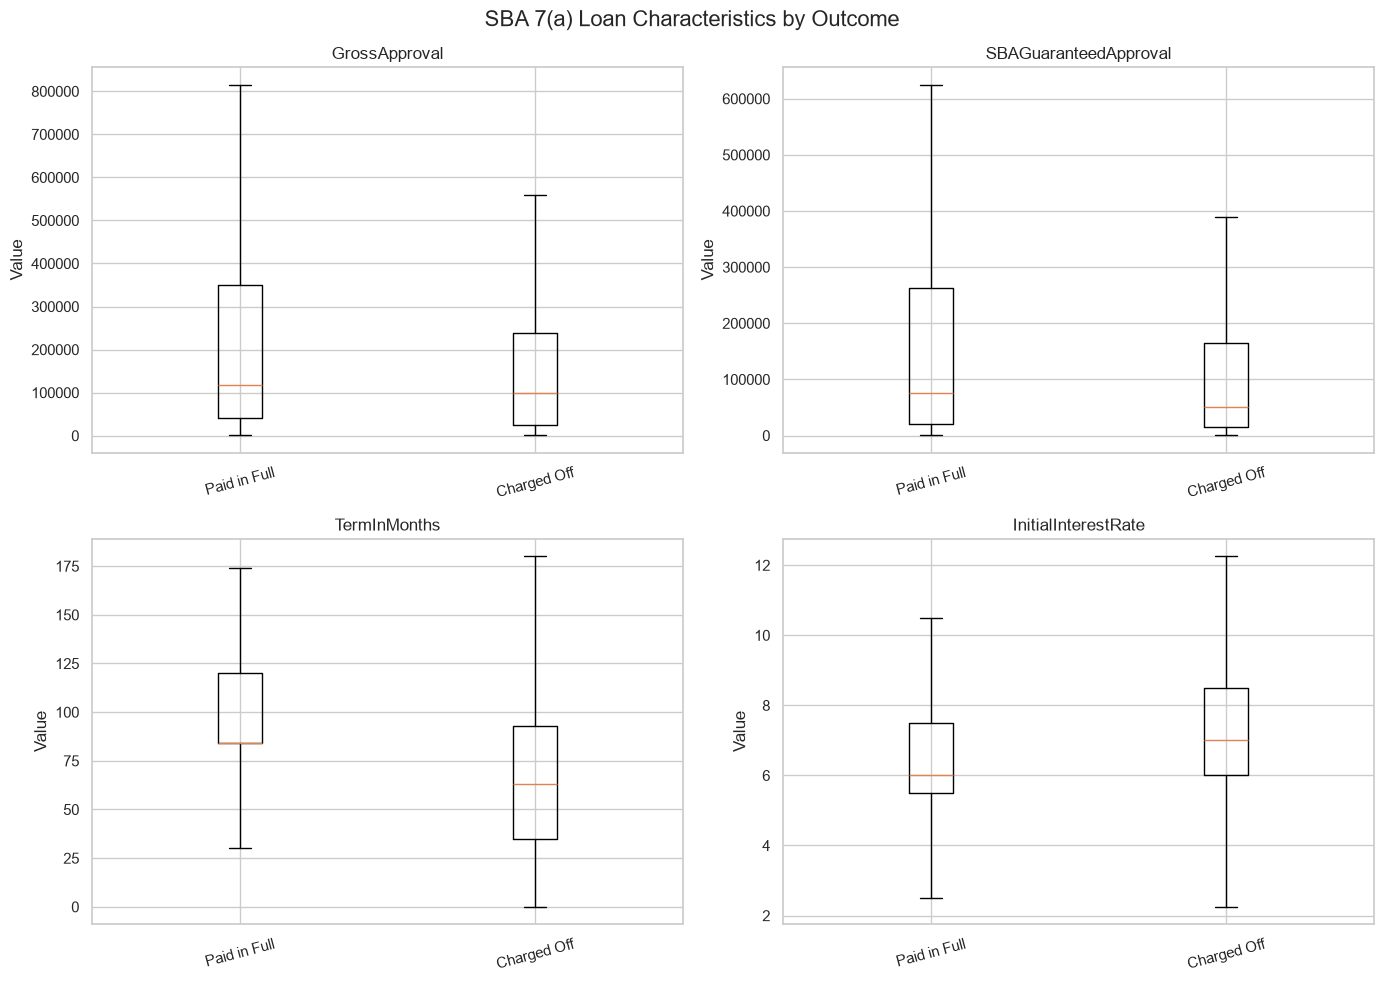

Paid-in-full loans: 462,922
Charged-off loans: 41,046
SBA 7(a) hypothesis test results:


,Characteristic,Paid_In_Full_Count,Charged_Off_Count,Paid_In_Full_Median,Charged_Off_Median,Median_Difference,P_Value,Adjusted_P_Value,Significant
0,GrossApproval,462922,41046,117000.0,100000.0,-17000.0,0.0,0.0,True
1,SBAGuaranteedApproval,462922,41046,75000.0,50000.0,-25000.0,0.0,0.0,True
2,TermInMonths,462922,41046,84.0,63.0,-21.0,0.0,0.0,True
3,InitialInterestRate,462922,41046,6.0,7.0,1.0,0.0,0.0,True


In [20]:

# Question 4: SBA 7(a) Hypothesis Testing

from scipy.stats import mannwhitneyu
import pandas as pd
import numpy as np

# Select relevant characteristics
hypothesis_data_7a = df7a[[
    "GrossApproval",
    "SBAGuaranteedApproval",
    "TermInMonths",
    "InitialInterestRate",
    "LoanStatus"
]].copy()

# Convert numerical columns
numeric_columns_7a = [
    "GrossApproval",
    "SBAGuaranteedApproval",
    "TermInMonths",
    "InitialInterestRate"
]

for column in numeric_columns_7a:
    hypothesis_data_7a[column] = pd.to_numeric(
        hypothesis_data_7a[column], errors="coerce"
    )

# Clean loan status
hypothesis_data_7a["LoanStatus"] = (
    hypothesis_data_7a["LoanStatus"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Keep explicitly resolved outcomes
hypothesis_data_7a = hypothesis_data_7a[
    hypothesis_data_7a["LoanStatus"].isin(["P I F", "CHGOFF"])
].copy()

# Define outcome groups
paid_in_full_7a = hypothesis_data_7a[
    hypothesis_data_7a["LoanStatus"] == "P I F"
]

charged_off_7a = hypothesis_data_7a[
    hypothesis_data_7a["LoanStatus"] == "CHGOFF"
]

# Boxplots of characteristics by loan outcome

numeric_columns_7a = [
    "GrossApproval",
    "SBAGuaranteedApproval",
    "TermInMonths",
    "InitialInterestRate"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for axis, column in zip(axes.flat, numeric_columns_7a):
    boxplot_data = [
        paid_in_full_7a[column].dropna(),
        charged_off_7a[column].dropna()
    ]

    axis.boxplot(
        boxplot_data,
        tick_labels=["Paid in Full", "Charged Off"],
        showfliers=False
    )

    axis.set_title(column)
    axis.set_ylabel("Value")
    axis.tick_params(axis="x", rotation=15)

fig.suptitle(
    "SBA 7(a) Loan Characteristics by Outcome",
    fontsize=16
)

plt.tight_layout()
plt.show()
print(f"Paid-in-full loans: {len(paid_in_full_7a):,}")
print(f"Charged-off loans: {len(charged_off_7a):,}")


# Compare characteristics and conduct hypothesis tests
hypothesis_results_7a = []

for column in numeric_columns_7a:
    paid_values = paid_in_full_7a[column].dropna()
    charged_values = charged_off_7a[column].dropna()

    if len(paid_values) > 0 and len(charged_values) > 0:
        test_result = mannwhitneyu(
            paid_values,
            charged_values,
            alternative="two-sided"
        )

        hypothesis_results_7a.append({
            "Characteristic": column,
            "Paid_In_Full_Count": len(paid_values),
            "Charged_Off_Count": len(charged_values),
            "Paid_In_Full_Median": paid_values.median(),
            "Charged_Off_Median": charged_values.median(),
            "Median_Difference": (
                charged_values.median() - paid_values.median()
            ),
            "P_Value": test_result.pvalue
        })

hypothesis_results_7a = pd.DataFrame(hypothesis_results_7a)

# Adjust for testing multiple characteristics
hypothesis_results_7a["Adjusted_P_Value"] = np.minimum(
    hypothesis_results_7a["P_Value"] * len(hypothesis_results_7a),
    1
)

hypothesis_results_7a["Significant"] = (
    hypothesis_results_7a["Adjusted_P_Value"] < 0.05
)

print("SBA 7(a) hypothesis test results:")
display(hypothesis_results_7a.round(4))

Paid-in-full records: 36,624
Charged-off records: 923
Median characteristics by loan outcome:


GrossApproval                      ThirdPartyDollars            \
                   count    median       mean             count    median   
LoanStatus                                                                  
CHGOFF               923  494000.0  754052.00               916  632168.0   
PIF                36624  455000.0  712691.19             36524  577500.0   

                       TermInMonths                
                  mean        count median   mean  
LoanStatus                                         
CHGOFF      1062942.31          923  240.0  229.6  
PIF          959871.09        36624  240.0  239.1

SBA 504 hypothesis test results:


,Characteristic,Paid_In_Full_Count,Charged_Off_Count,Paid_In_Full_Median,Charged_Off_Median,Median_Difference,P_Value,Adjusted_P_Value,Significant
0,GrossApproval,36624,923,455000.0,494000.0,39000.0,0.3043,0.9129,False
1,ThirdPartyDollars,36524,916,577500.0,632168.0,54668.0,0.0330,0.0991,False
2,TermInMonths,36624,923,240.0,240.0,0.0,0.0000,0.0000,True


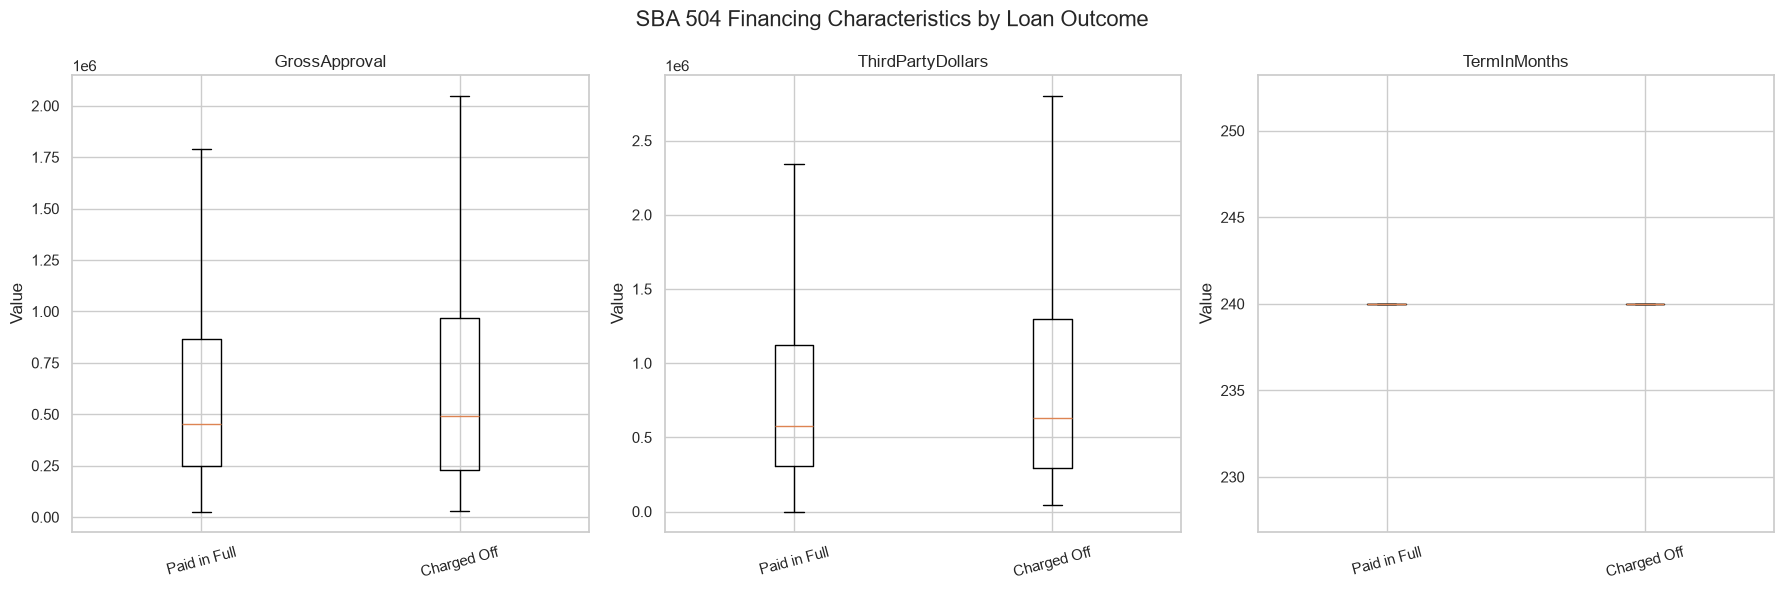

In [21]:

# Question 4: SBA 504 Hypothesis Testing

from scipy.stats import mannwhitneyu
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Select relevant characteristics
hypothesis_data_504 = df504[[
    "GrossApproval",
    "ThirdPartyDollars",
    "TermInMonths",
    "LoanStatus"
]].copy()

# Convert numerical columns
numeric_columns_504 = [
    "GrossApproval",
    "ThirdPartyDollars",
    "TermInMonths"
]

for column in numeric_columns_504:
    hypothesis_data_504[column] = pd.to_numeric(
        hypothesis_data_504[column], errors="coerce"
    )

# Clean loan status
hypothesis_data_504["LoanStatus"] = (
    hypothesis_data_504["LoanStatus"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Keep loans with explicitly resolved outcomes
hypothesis_data_504 = hypothesis_data_504[
    hypothesis_data_504["LoanStatus"].isin(["PIF", "CHGOFF"])
].copy()

# Define outcome groups
paid_in_full_504 = hypothesis_data_504[
    hypothesis_data_504["LoanStatus"] == "PIF"
]

charged_off_504 = hypothesis_data_504[
    hypothesis_data_504["LoanStatus"] == "CHGOFF"
]

print(f"Paid-in-full records: {len(paid_in_full_504):,}")
print(f"Charged-off records: {len(charged_off_504):,}")

# Summary statistics by outcome
print("Median characteristics by loan outcome:")

outcome_summary_504 = hypothesis_data_504.groupby("LoanStatus")[
    numeric_columns_504
].agg(["count", "median", "mean"]).round(2)

display(outcome_summary_504)

# Compare characteristics and conduct hypothesis tests
hypothesis_results_504 = []

for column in numeric_columns_504:
    paid_values = paid_in_full_504[column].dropna()
    charged_values = charged_off_504[column].dropna()

    if len(paid_values) > 0 and len(charged_values) > 0:
        test_result = mannwhitneyu(
            paid_values,
            charged_values,
            alternative="two-sided"
        )

        hypothesis_results_504.append({
            "Characteristic": column,
            "Paid_In_Full_Count": len(paid_values),
            "Charged_Off_Count": len(charged_values),
            "Paid_In_Full_Median": paid_values.median(),
            "Charged_Off_Median": charged_values.median(),
            "Median_Difference": (
                charged_values.median() - paid_values.median()
            ),
            "P_Value": test_result.pvalue
        })

hypothesis_results_504 = pd.DataFrame(hypothesis_results_504)

# Adjust p-values for multiple hypothesis tests
if not hypothesis_results_504.empty:
    hypothesis_results_504["Adjusted_P_Value"] = np.minimum(
        hypothesis_results_504["P_Value"]
        * len(hypothesis_results_504),
        1
    )

    hypothesis_results_504["Significant"] = (
        hypothesis_results_504["Adjusted_P_Value"] < 0.05
    )

    print("SBA 504 hypothesis test results:")
    display(hypothesis_results_504.round(4))
else:
    print("No hypothesis tests could be completed.")

# Visualise financing amounts and loan terms by outcome
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for axis, column in zip(axes, numeric_columns_504):
    boxplot_data = [
        paid_in_full_504[column].dropna(),
        charged_off_504[column].dropna()
    ]

    axis.boxplot(
        boxplot_data,
        tick_labels=["Paid in Full", "Charged Off"],
        showfliers=False
    )

    axis.set_title(column)
    axis.set_ylabel("Value")
    axis.tick_params(axis="x", rotation=15)

fig.suptitle(
    "SBA 504 Financing Characteristics by Loan Outcome",
    fontsize=16
)

plt.tight_layout()
plt.show()